# Uniform sampling vs. random sampling + $\ell_1$

The Nyquist-Shannon theorem says that a signal whose highest frequency is
$f_{\max}$ can be rebuilt from **uniform** samples by sinc interpolation if the
sampling rate is at least $2f_{\max}$. Below that rate the samples alias, and no
linear method can undo it. Compressed sensing changes two things at once: the
samples are taken at **random** times, and the reconstruction uses the prior
that the signal has only a few active frequencies. This notebook gives both
approaches exactly the same number of samples and compares them.

**In this notebook you will**

* build an orthonormal real Fourier basis and a signal with 4 tones;
* reconstruct it from 48 uniform samples (sinc interpolation) and from 48 random
  samples (basis pursuit, solved as a linear program);
* sweep the number of samples and see that uniform sampling is governed by the
  highest frequency, while random sampling is governed by the number of tones.

**Before this notebook:** `cs_recovery_fista` (ISTA, FISTA, OMP and a first
sub-Nyquist example). **Next:** `cs_portrait_fista` (compressed sensing on an
image).

**Runtime:** under 10 seconds (the sweep solves 290 small linear programs).

## The recovery problem

Let $\boldsymbol{x}\in\mathbb{R}^N$ be the signal on a grid of $N$ points,
$\boldsymbol{\Psi}\in\mathbb{R}^{N\times N}$ an orthonormal Fourier basis so that
$\boldsymbol{x}=\boldsymbol{\Psi}\boldsymbol{s}$, and
$\mathbf{C}\in\mathbb{R}^{M\times N}$ the matrix that keeps $M$ chosen rows of
the identity (the sample positions), so the data are
$\boldsymbol{y}=\mathbf{C}\boldsymbol{x}\in\mathbb{R}^M$. Compressed sensing
solves **basis pursuit**,

$$\min_{\boldsymbol{s}}\|\boldsymbol{s}\|_1\quad\text{s.t.}\quad
  \mathbf{C}\boldsymbol{\Psi}\boldsymbol{s}=\boldsymbol{y}:$$

among all coefficient vectors that reproduce the samples exactly, take the one
with the smallest $\ell_1$ norm. It is solved here as a linear program (details
in Section 1). With the same number of samples, far below Nyquist, one method
fails and the other is exact.

**Setup.** Imports, the course plot style, and the output folder for figures.
`linprog` from SciPy will solve basis pursuit.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from pyutils import set_plot_style, save_dual, fg, muted
set_plot_style()

FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)

## Parameters (edit these)

* `SEED`: random seed for the tones, phases, amplitudes and sample positions.
* `N`: grid points over one second, so the grid spacing is $1/N$ s and the
  highest representable frequency is $N/2$ Hz.
* `K_TONES`: number of active frequencies (tones) in the signal.
* `F_RANGE`: the integer band, in Hz, the tones are drawn from (upper end
  excluded).
* `M_SHOW`: number of samples in the single-experiment figure.
* `M_SWEEP`: sample counts tried in the sweep (8, 16, ..., 232).
* `N_TRIALS`: number of independent random sample sets per $M$ in the sweep.

In [2]:
SEED = 0
N = 256                 # grid points over one second (index = time in 1/N s)
K_TONES = 4             # active frequencies
F_RANGE = (20, 100)     # tones drawn from this integer-frequency band [Hz]
M_SHOW = 48             # samples in the single-trace figure
M_SWEEP = np.arange(8, 233, 8)
N_TRIALS = 10           # random sample sets per M in the sweep

rng = np.random.default_rng(SEED)

## 1. A 4-tone signal and the real Fourier basis

**The basis.** $\boldsymbol{\Psi}$ has $N$ orthonormal columns: a constant
column $1/\sqrt{N}$, then for every integer frequency $f=1,\dots,N/2-1$ a cosine
and a sine column $\sqrt{2/N}\cos(2\pi f t/N)$ and $\sqrt{2/N}\sin(2\pi f t/N)$,
and finally the alternating column $\cos(\pi t)/\sqrt{N}$ at $f=N/2$. Here $t$ is
the grid index $0,\dots,N-1$. The list `labels` remembers the frequency and type
(`'c'` or `'s'`) of each column. Because $\boldsymbol{\Psi}$ is orthonormal,
the coefficients of any signal are simply
$\boldsymbol{s}=\boldsymbol{\Psi}^\top\boldsymbol{x}$.

**The signal.** We draw `K_TONES` distinct integer frequencies from `F_RANGE`, an
amplitude between 0.6 and 1.4 and a random phase for each, and sum the cosines.
A cosine with an arbitrary phase is a combination of one cosine and one sine
column, so each tone occupies 2 columns and $\|\boldsymbol{s}\|_0=2K=8$, where
$\|\boldsymbol{s}\|_0$ counts the nonzero coefficients. The Nyquist rate is
$2f_{\max}$, twice the highest tone.

In [3]:
t = np.arange(N)
cols, labels = [np.ones(N) / np.sqrt(N)], [(0, 'c')]
for f in range(1, N // 2):
    cols += [np.sqrt(2 / N) * np.cos(2 * np.pi * f * t / N), np.sqrt(2 / N) * np.sin(2 * np.pi * f * t / N)]
    labels += [(f, 'c'), (f, 's')]
cols.append(np.cos(np.pi * t) / np.sqrt(N)); labels.append((N // 2, 'c'))   # f = N/2: only a cosine exists
PSI = np.column_stack(cols)
assert np.allclose(PSI.T @ PSI, np.eye(N)), "real Fourier basis must be orthonormal"

freqs = np.sort(rng.choice(np.arange(*F_RANGE), K_TONES, replace=False))
amps, phases = rng.uniform(0.6, 1.4, K_TONES), rng.uniform(0, 2 * np.pi, K_TONES)


def signal(tt):
    # works for any (also non-integer) time index tt, so uniform samples can fall between grid points
    return sum(a * np.cos(2 * np.pi * f * tt / N + p) for a, f, p in zip(amps, freqs, phases))


x = signal(t)
s_true = PSI.T @ x                     # coefficients in the orthonormal basis
f_max = freqs.max(); nyquist = 2 * f_max
print(f"tones {freqs} Hz; f_max = {f_max} Hz -> Nyquist needs {nyquist} samples/s; "
      f"||s||_0 = {np.sum(np.abs(s_true) > 1e-9)}")
assert np.sum(np.abs(s_true) > 1e-9) == 2 * K_TONES

tones [41 60 69 85] Hz; f_max = 85 Hz -> Nyquist needs 170 samples/s; ||s||_0 = 8


The tones are at 41, 60, 69 and 85 Hz. The highest is 85 Hz, so uniform sampling
needs at least 170 samples per second. The coefficient vector has exactly 8
nonzeros out of 256, as expected for 4 tones.

### The two reconstruction methods

**Uniform samples + sinc interpolation.** `uniform_times(M)` places $M$ samples
evenly over the second (at times $iN/M$ in grid units, which need not be integers).
`sinc_reconstruct(M)` is band-limited interpolation, done in the frequency domain:

1. Take the DFT of the $M$ uniform samples. It holds the frequencies
   $0,\dots,M/2$ Hz.
2. Copy those coefficients into the low-frequency slots of a length-$N$ spectrum
   and leave all higher slots at zero (zero padding). For even $M$ the bin at
   exactly $M/2$ is split equally between the positive and negative side.
3. Inverse DFT and rescale by $N/M$.

This is exact whenever $f_{\max}<M/2$. If a tone lies above $M/2$, its samples
are identical to those of a lower "alias" frequency, and the method returns
that wrong, lower frequency instead.

**Random samples + basis pursuit.** `basis_pursuit(idx)` takes integer sample
positions `idx` (the rows that $\mathbf{C}$ keeps) and sets
$\mathbf{A}=\mathbf{C}\boldsymbol{\Psi}$, the rows of $\boldsymbol{\Psi}$ at those
positions. The $\ell_1$ norm is not linear, so we use the standard trick: write
$\boldsymbol{s}=\boldsymbol{u}-\boldsymbol{v}$ with $\boldsymbol{u},\boldsymbol{v}\ge\boldsymbol{0}$,
and solve the linear program

$$\min_{\boldsymbol{u},\boldsymbol{v}}\ \mathbf{1}^\top\boldsymbol{u}+\mathbf{1}^\top\boldsymbol{v}
  \quad\text{s.t.}\quad
  \begin{bmatrix}\mathbf{A} & -\mathbf{A}\end{bmatrix}
  \begin{bmatrix}\boldsymbol{u}\\ \boldsymbol{v}\end{bmatrix}=\boldsymbol{y},\qquad
  \boldsymbol{u},\boldsymbol{v}\ge\boldsymbol{0}.$$

In words: $\boldsymbol{u}$ holds the positive parts of $\boldsymbol{s}$ and
$\boldsymbol{v}$ the negative parts. The objective is the sum of all entries.
At the optimum, $u_j$ and $v_j$ are never both positive (that would waste
objective), so $\mathbf{1}^\top\boldsymbol{u}+\mathbf{1}^\top\boldsymbol{v}=\|\boldsymbol{s}\|_1$.
The equality constraint says the samples are reproduced exactly. SciPy's HiGHS
solver returns $(\boldsymbol{u},\boldsymbol{v})$; we form
$\boldsymbol{s}=\boldsymbol{u}-\boldsymbol{v}$ and the full signal
$\boldsymbol{\Psi}\boldsymbol{s}$.

`relerr` is the relative error $\|\hat{\boldsymbol{x}}-\boldsymbol{x}\|_2/\|\boldsymbol{x}\|_2$
on the full grid.

In [4]:
def uniform_times(M):
    return np.arange(M) * N / M


def sinc_reconstruct(M):
    """Band-limited (periodic sinc) interpolation from M uniform samples.

    Exact whenever f_max < M/2; equivalent to zero-padding the samples' DFT."""
    X = np.fft.fft(signal(uniform_times(M)))
    Z = np.zeros(N, complex); h = M // 2
    if M % 2:
        Z[:h + 1] = X[:h + 1]; Z[-h:] = X[-h:]
    else:
        # even M: split the bin at exactly M/2 between +f and -f
        Z[:h] = X[:h]; Z[-h + 1:] = X[-h + 1:]; Z[h] += X[h] / 2; Z[-h] += X[h] / 2
    return np.real(np.fft.ifft(Z)) * N / M


def basis_pursuit(idx):
    """min ||s||_1 s.t. PSI[idx] s = x[idx], as an LP in (u, v) >= 0."""
    A = PSI[idx]                                    # A = C Psi
    res = linprog(np.ones(2 * N), A_eq=np.hstack([A, -A]), b_eq=x[idx],
                  bounds=(0, None), method='highs')
    assert res.status == 0, res.message
    s = res.x[:N] - res.x[N:]                       # s = u - v
    return PSI @ s, s


def relerr(a):
    return np.linalg.norm(a - x) / np.linalg.norm(x)

## 2. One experiment at $M=48$ samples

Both methods get `M_SHOW` $=48$ samples in one second. That is
$48/(2f_{\max})\approx0.28$ of the Nyquist rate. The uniform method uses 48
evenly spaced times; the random method uses 48 distinct grid points drawn at
random. The asserts check that the setting really is far below Nyquist, that
sinc interpolation fails, that basis pursuit is exact, and that the nonzero
coefficients basis pursuit finds sit at exactly the true tone frequencies.

In [5]:
t_u = uniform_times(M_SHOW)
idx_r = np.sort(rng.choice(N, M_SHOW, replace=False))   # random sample positions
x_sinc = sinc_reconstruct(M_SHOW)
x_cs, s_cs = basis_pursuit(idx_r)
e_sinc, e_cs = relerr(x_sinc), relerr(x_cs)
print(f"M = {M_SHOW} ({M_SHOW/nyquist:.2f} x Nyquist): sinc error {e_sinc:.3f}, CS error {e_cs:.1e}")
assert M_SHOW < nyquist / 3, "the demonstration must sit well below Nyquist"
assert e_sinc > 0.5, "uniform sub-Nyquist sampling must alias badly"
assert e_cs < 1e-6, "random samples + basis pursuit must be exact"
# frequencies of the nonzero recovered coefficients must equal the true tones
assert set(np.unique([labels[i][0] for i in np.flatnonzero(np.abs(s_cs) > 1e-6)])) == set(freqs)

M = 48 (0.28 x Nyquist): sinc error 1.414, CS error 6.3e-13


At 0.28 times the Nyquist rate, sinc interpolation has relative error 1.414,
while basis pursuit has $6.3\times10^{-13}$, which is solver precision. The value
1.414 is about $\sqrt{2}$: that is the error you get when the reconstruction has
the same energy as the truth but lives at entirely different (aliased)
frequencies, so the two are orthogonal. With 48 uniform samples only frequencies
below 24 Hz can be represented, and all four tones lie above that.

### Figure: the two reconstructions over one second

The next cell plots both reconstructions against the truth and saves the figure
as `cs_uniform_vs_random` (light and dark versions).

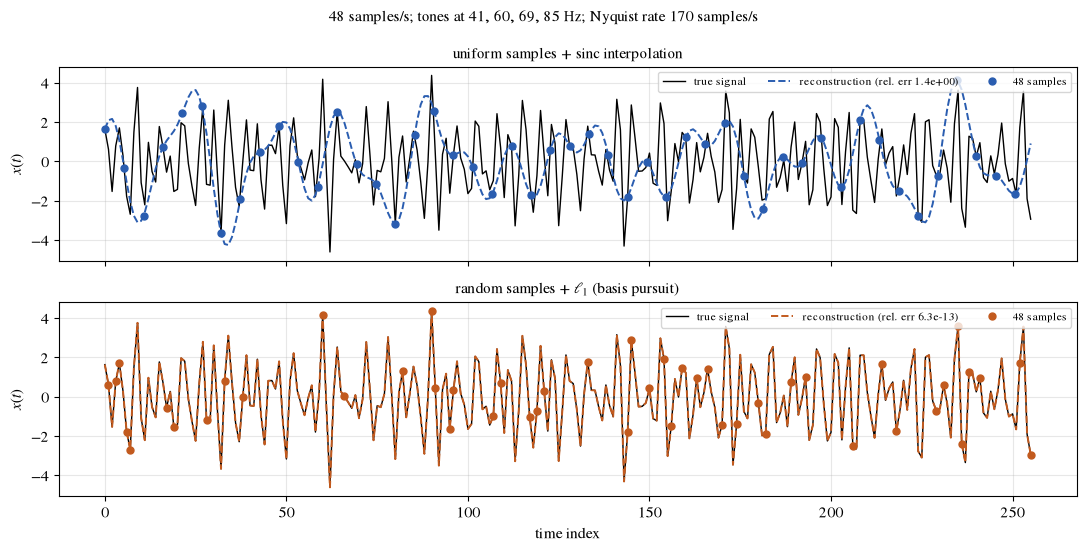

In [6]:
def plot_uniform_vs_random():
    fig, ax = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True)
    for a, rec, ts, name, col, e in [
            (ax[0], x_sinc, t_u, 'uniform samples + sinc interpolation', 'C0', e_sinc),
            (ax[1], x_cs, idx_r, r'random samples + $\ell_1$ (basis pursuit)', 'C1', e_cs)]:
        a.plot(t, x, color=fg(), lw=1.0, label='true signal')
        a.plot(t, rec, color=col, lw=1.4, ls='--', label=f'reconstruction (rel. err {e:.1e})')
        a.plot(ts, signal(ts), 'o', color=col, ms=5, label=f'{M_SHOW} samples')
        a.set_title(name, fontsize=11); a.set_ylabel('$x(t)$')
        a.legend(fontsize=8, loc='upper right', ncol=3)
    ax[1].set_xlabel('time index')
    fig.suptitle(f'{M_SHOW} samples/s; tones at {", ".join(map(str, freqs))} Hz; '
                 f'Nyquist rate {nyquist} samples/s', fontsize=11)
    plt.tight_layout()


save_dual(plot_uniform_vs_random, 'cs_uniform_vs_random', FIG)
plt.show()

**How to read this figure.** Both panels show the same one second of signal; the
horizontal axis is the time index $0,\dots,255$ (one step is $1/256$ s) and the
vertical axis is $x(t)$. The thin black line is the true 4-tone signal. *Top:*
blue dots are the 48 evenly spaced samples and the blue dashed line is the sinc
reconstruction. *Bottom:* orange dots are the 48 random samples and the orange
dashed line is the basis-pursuit reconstruction. Each legend gives the relative
error, and the suptitle lists the tones and the Nyquist rate.

**What it shows.** *Top:* the blue dashed curve passes through every blue sample,
yet it is a slow, smooth wave that ignores the fast wiggles of the black signal
(relative error $1.4$). It is a perfectly valid signal that matches the data; it
is just the wrong one, made of aliased low frequencies. *Bottom:* the orange
dashed curve lies on top of the black curve everywhere, including far from any
sample (relative error $6.3\times10^{-13}$). The random samples are clumped in
some places and sparse in others, yet that is enough. The takeaway: the same
sample budget gives a useless answer with uniform sampling and linear
reconstruction, and an exact answer with random sampling and a sparsity prior.

## 3. Error versus the number of samples

One experiment could be luck. We now sweep the number of samples $M$ over
`M_SWEEP` $=8,16,\dots,232$:

* **Uniform + sinc** is deterministic, so one run per $M$ (`err_u`).
* **Random + $\ell_1$** is repeated with `N_TRIALS` $=10$ fresh random sample
  sets per $M$ (`err_r`, shape $29\times10$). A trial counts as exact recovery
  if its relative error is below $10^{-6}$; `succ` is the fraction of exact
  trials at each $M$.
* `M_cs` is the smallest $M$ in the sweep at which at least 90% of trials are
  exact.

Theory predicts that uniform sampling needs $M\ge2f_{\max}$, while random
sampling with $\ell_1$ needs a small multiple of the *number of nonzeros*
$\|\boldsymbol{s}\|_0$, independent of where the tones sit in the spectrum.

In [7]:
err_u, err_r = [], []
for M in M_SWEEP:
    err_u.append(relerr(sinc_reconstruct(M)))
    err_r.append([relerr(basis_pursuit(np.sort(rng.choice(N, M, replace=False)))[0])
                  for _ in range(N_TRIALS)])
err_u, err_r = np.array(err_u), np.array(err_r)
succ = np.mean(err_r < 1e-6, axis=1)                  # fraction of exact trials per M
M_cs = M_SWEEP[np.argmax(succ >= 0.9)]                # first M with >= 90% success
print("M      :", M_SWEEP)
print("sinc   :", np.round(err_u, 3))
print("CS succ:", succ)
print(f"CS reaches 90% exact recovery at M = {M_cs} = {M_cs/(2*K_TONES):.1f} x ||s||_0 "
      f"({M_cs/nyquist:.2f} x Nyquist)")
assert M_cs <= nyquist / 3, "CS must succeed far below the Nyquist count"
assert np.all(err_u[M_SWEEP < nyquist / 2] > 0.3), "sinc must fail well below Nyquist"
assert np.all(err_u[M_SWEEP > nyquist] < 1e-10), "sinc must be exact above Nyquist"

M      : [  8  16  24  32  40  48  56  64  72  80  88  96 104 112 120 128 136 144
 152 160 168 176 184 192 200 208 216 224 232]
sinc   : [1.456 1.472 1.397 1.414 1.397 1.414 1.414 1.414 1.414 1.414 1.213 1.213
 1.213 1.213 0.959 0.934 0.934 0.688 0.688 0.688 0.688 0.    0.    0.
 0.    0.    0.    0.    0.   ]
CS succ: [0.  0.  0.  0.5 0.7 1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.
 1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1. ]
CS reaches 90% exact recovery at M = 48 = 6.0 x ||s||_0 (0.28 x Nyquist)


**Reading the table.** The sinc error does not fall smoothly; it drops in steps,
one step each time $M/2$ passes a tone frequency and that tone stops aliasing.
It sits near 1.414 up to $M=80$, falls to 1.213 at $M=88$ (now $M/2=44$ exceeds
the 41 Hz tone), to 0.959 and then 0.934 around $M=120$–$136$ (the 60 Hz tone),
to 0.688 from $M=144$ (the 69 Hz tone), and to 0 from $M=176$, the first value
above the Nyquist count of 170. Random sampling with $\ell_1$ fails at
$M=8$–$24$, succeeds in 50% of trials at $M=32$ and 70% at $M=40$, and in every
trial from $M=48$ on. So the 90% threshold is $M=48$, which is $6.0$ times
$\|\boldsymbol{s}\|_0$ and only 0.28 of the Nyquist count.

### Figure: error against sample budget

Saved as `cs_uniform_vs_random_sweep`.

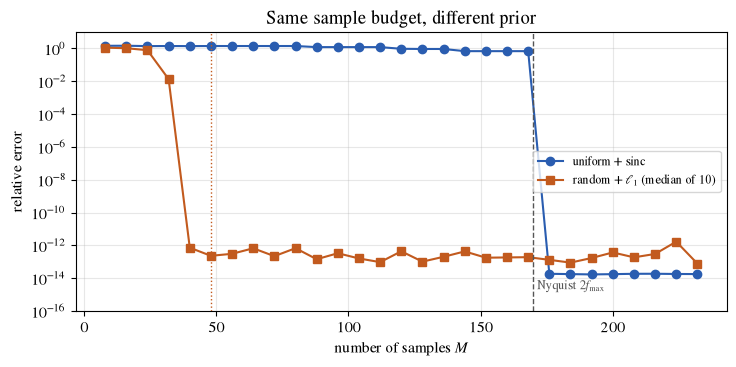

In [8]:
def plot_error_vs_m():
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    ax.semilogy(M_SWEEP, err_u, 'o-', color='C0', label='uniform + sinc')
    med = np.median(err_r, axis=1)                    # median over the random trials
    ax.semilogy(M_SWEEP, np.maximum(med, 1e-16), 's-', color='C1', label=r'random + $\ell_1$ (median of 10)')
    ax.axvline(nyquist, color=muted(), ls='--', lw=1)
    ax.text(nyquist, 2e-15, r' Nyquist $2f_{\max}$', fontsize=9, color=muted())
    ax.axvline(M_cs, color='C1', ls=':', lw=1)
    ax.set(xlabel='number of samples $M$', ylabel='relative error', ylim=(1e-16, 10),
           title='Same sample budget, different prior')
    ax.legend(fontsize=9, loc='center right'); plt.tight_layout()


save_dual(plot_error_vs_m, 'cs_uniform_vs_random_sweep', FIG)
plt.show()

**How to read this figure.** The horizontal axis is the number of samples $M$;
the vertical axis is the relative reconstruction error on a log scale. Blue
circles are uniform sampling with sinc interpolation. Orange squares are random
sampling with basis pursuit, showing the median over the 10 trials at each $M$.
The grey dashed vertical line marks the Nyquist count $2f_{\max}=170$, and the
orange dotted vertical line marks $M=48$, where random sampling first reaches
90% exact recovery.

**What it shows.** The blue curve stays at order 1 (no useful reconstruction)
all the way to the Nyquist line, stepping down slightly as individual tones stop
aliasing, and then falls to round-off level just after it. The orange curve
falls just as sharply, but already between $M=24$ and $M=40$, and
from $M=48$ it stays at solver precision. Between the two drops lies a wide range,
from $M=48$ to $M=168$, where the random method is exact and the uniform method
is useless. The tiny residual errors of either method to the right are just
round-off of different solvers. The takeaway: the position of the blue drop is
set by the highest frequency; the position of the orange drop is set by how many
frequencies are active.

## Summary

* Uniform sampling at 48 samples/s cannot represent tones up to
  $f_{\max}=85$ Hz: they alias, and sinc interpolation returns a different signal
  (relative error 1.414).
* The same number of **random** samples, decoded with the sparsity prior through
  basis pursuit, returns the signal to solver precision ($6.3\times10^{-13}$).
* Over the sweep, sinc becomes exact only above the Nyquist count of 170 samples,
  while random sampling with $\ell_1$ is exact in at least 90% of trials from
  $M=48$, which is $6.0\times\|\boldsymbol{s}\|_0$.
* Nyquist charges for the *bandwidth*; compressed sensing charges for the
  *number of active frequencies*.

## Try this

All changes go in the **Parameters** cell; then re-run the whole notebook.

1. **Move the tones up.** Set `F_RANGE = (100, 127)`. The Nyquist count rises to
   over 200, so the blue drop moves right (possibly past the end of `M_SWEEP`).
   The orange threshold should stay about where it is, because the number of
   tones has not changed.
2. **More tones.** Set `K_TONES = 8`, so $\|\boldsymbol{s}\|_0=16$. Expect the
   orange threshold to move right, roughly in proportion to the number of
   nonzeros, while the blue curve depends only on the highest tone. The assert
   that 48 samples are enough may now fail: that is the point of the experiment.
3. **Smoother statistics.** Set `N_TRIALS = 50`. The success fractions in the
   transition zone ($M=32$–$40$) become more reliable; the overall picture should
   not change. The run takes several times longer.
4. **Another random draw.** Change `SEED`. The tones, phases and sample sets
   change. Check whether the 90% threshold is still about 6 times
   $\|\boldsymbol{s}\|_0$. Some seeds draw a low $f_{\max}$, which shrinks the
   gap to Nyquist and may trip the asserts that require a large gap.